# 02 Portfolio evaluation

**Question: do forecast gains translate into better risk-adjusted performance in
volatility-managed portfolios?** This notebook answers it block by block. Each block in
`BLOCKS` (`models/research_config.py`) asks one sub-question of the research question, such as
"does macro help within GARCH?" or "is VIX doing all the work?", and is answered on the portfolio
side here, with the same pairs the forecast evaluation tests with Diebold-Mariano.

Every managed portfolio built in `01_build_portfolios.ipynb` is compared with **two benchmarks**,
and the models within each block are compared **with each other**:

| Comparison | Question it answers |
|---|---|
| model vs **buy-and-hold (BH)** | Does volatility timing with this forecast work at all? |
| model vs **`hist_rw`** | Does this forecast add anything beyond the simplest volatility timing (Moreira & Muir: σ̂²ₜ₊₁ = RVₜ)? |
| model a vs model b, within a block | Does the addition in a (macro, VIX, non-linearity) give a better portfolio? |

**Layout.** Part A is the cyclical bucket, the headline: an overview, then one section per block,
then a scoreboard. Part B repeats the comparisons for each ETF on its own. Part C checks that the
conclusions hold under the expanding σ̄² and separates timing from re-levering.

## Setup

In [1]:
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path("..").resolve()))   # models/: research_config and utils

from research_config import BLOCKS
from utils.portfolio_utils import (
    BH, CONTROL, PORTFOLIO_DIR, EVAL_DIR, load_portfolios,
    performance_row, evaluate_bucket, alpha_regression, alpha_vs_bh_and_control,
    compare_pair, per_etf_table, pct_capped, pct_capped_pooled,
    block_models, stars, outcome, verdict, plot_growth, heatmap,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:.3f}".format)

### Load the saved portfolios

The models, comparison pairs, specifications and cap come from `results/portfolios/run_info.json`,
so this notebook always matches the latest run of `01_build_portfolios.ipynb`. Pairs whose models
were not built (for example those using `en_vix_only`, which has no forecasts yet) are listed and
left out.

In [2]:
run_info = json.loads((PORTFOLIO_DIR / "run_info.json").read_text())
MODELS, SPECS, K_CAP = run_info["variants"], run_info["specs"], run_info["k_cap"]
MAIN_SPEC, BENCHMARK = run_info["main_spec"], run_info["benchmark"]
ROBUST_SPEC = next(s for s in SPECS if s != MAIN_SPEC)
pairs = pd.DataFrame(run_info["pairs"]).set_index("pair")
skipped = pd.DataFrame(run_info["skipped_pairs"], columns=["pair", "block", "a", "b", "isolates", "missing"])

portfolios = {}
for spec in SPECS:
    portfolios[spec], xret = load_portfolios(spec)
    assert set(MODELS) <= set(portfolios[spec]), f"{spec}: saved models do not match run_info"
TICKERS = list(xret.columns)
bh = xret.mean(axis=1)

print("Models:", MODELS)
print(f"Benchmark: {BENCHMARK} | specifications: {SPECS} (main: {MAIN_SPEC})")
print(f"Out-of-sample window: {run_info['oos_window'][0]} to {run_info['oos_window'][1]}"
      f" ({len(xret)} months)")
print(f"\n{len(pairs)} pairs tested. Skipped (models not built yet):")
skipped

Models: ['hist_rw', 'garch', 'garch_midas_baa10y', 'ols_1m', 'en_no_macro', 'en_no_vix', 'en_full_macro', 'xgb_no_macro', 'xgb_no_vix', 'xgb_vix_only', 'xgb_full_macro']
Benchmark: hist_rw | specifications: ['fixed', 'expanding'] (main: fixed)
Out-of-sample window: 2008-03 to 2025-12 (214 months)

12 pairs tested. Skipped (models not built yet):


,pair,block,a,b,isolates,missing
0,B3.2,B3,en_vix_only,en_no_macro,VIX on its own,en_vix_only
1,B3.3,B3,en_full_macro,en_vix_only,other macro variables on top of VIX,en_vix_only
2,B5.3,B5,xgb_vix_only,en_vix_only,VIX only,en_vix_only


## Evaluation measures

The functions are in `utils/portfolio_utils.py`:

- **Performance** (`performance_row`): annualised mean and volatility of monthly excess returns,
  annualised Sharpe ratio (SR), maximum drawdown of the cumulative excess-return series, and
  average monthly turnover mean_t Σᵢ |wᵢ,ₜ − wᵢ,ₜ₋₁| over the weight held in each ETF. Buy-and-hold
  holds fixed weights, so its turnover is 0 by this measure.
- **Ledoit & Wolf (2008)** (`ledoit_wolf_sharpe_test`): tests H₀: SR(x) = SR(y) with the
  studentised circular block bootstrap (block 5, 5,000 draws). The two portfolios are tested
  directly, so the test uses their correlation: two models can both be insignificant against BH
  and still differ from each other, or the reverse. Sharpe ratios are tested on monthly data and
  reported annualised.
- **Alpha** (`alpha_regression`): f^σ_t = α + β · BH_t + εₜ with Newey-West standard errors
  (lag ⌊4(T/100)^{2/9}⌋ = 4). α is reported annualised.
- **% capped**: the share of ETF-months in which the base weight is at the cap k = 2.

Every managed portfolio is rescaled to the volatility of buy-and-hold, so mean returns, alphas
and drawdowns are compared at the same risk.

**Sign convention.** Each pair is (a, b), with a the richer model. ΔSR = SR(a) − SR(b), so a
positive ΔSR means the addition helps. Stars: \*\*\* p < 0.01, \*\* p < 0.05, \* p < 0.10.

## Run every test

One cell computes every test, so the sections below only display results (about 75 seconds):

1. every model against BH: performance, Ledoit-Wolf and alpha, for the bucket and each ETF;
2. Ledoit-Wolf tests of every model against `hist_rw` and of every block pair, for the bucket and
   each ETF.

Both under each σ̄² specification.

In [3]:
t0 = time.time()
bh_weights = pd.DataFrame(1 / len(TICKERS), index=xret.index, columns=TICKERS)

vs_bh, vs_bh_etf = {}, {}
for spec in SPECS:
    res = portfolios[spec]
    tbl = pd.DataFrame({BH: performance_row(bh, bh_weights)}
                       | {m: evaluate_bucket(res[m], bh) for m in MODELS}).T
    tbl["pct_capped"] = pd.Series({m: pct_capped_pooled(res[m]["weights_base"], K_CAP) for m in MODELS})
    vs_bh[spec] = tbl.rename_axis("portfolio")
    vs_bh_etf[spec] = pd.concat(
        {m: per_etf_table(res[m], xret).assign(pct_capped=pct_capped(res[m]["weights_base"], K_CAP))
         for m in MODELS},
        names=["model", "ETF"])

# Each model against the benchmark, then the block pairs (B0's pairs are already in the first list)
tests = list(dict.fromkeys([(m, BENCHMARK) for m in MODELS if m != BENCHMARK]
                           + list(zip(pairs["a"], pairs["b"]))))
lw = pd.concat({(spec, a, b): compare_pair(portfolios[spec][a], portfolios[spec][b], xret)
                for spec in SPECS for a, b in tests},
               names=["spec", "a", "b"])[["SR_a", "SR_b", "SR_diff", "LW_t", "LW_p"]].astype(float).sort_index()
print(f"Done in {time.time() - t0:.0f}s: {len(tests)} model pairs, {len(MODELS)} models vs BH, "
      f"bucket + {len(TICKERS)} ETFs, {len(SPECS)} specifications")

Done in 59s: 20 model pairs, 11 models vs BH, bucket + 5 ETFs, 2 specifications


Helpers that lay out each block's tables, plot and verdicts from the results above.

In [4]:
def bench_table(models, spec=MAIN_SPEC):
    # BH, the benchmark and `models`: SR, tests against BH and the benchmark, risk, robustness
    rows = [BH, BENCHMARK] + [m for m in models if m != BENCHMARK]
    main, rob = vs_bh[spec], vs_bh[ROBUST_SPEC]
    vs_rw = lw.loc[spec].xs("Cyclical", level="ETF")
    rw = lambda m, col: vs_rw.at[(m, BENCHMARK), col] if (m, BENCHMARK) in vs_rw.index else np.nan
    return pd.DataFrame({
        "SR": main.loc[rows, "ann_sharpe"],
        "ΔSR vs BH": main.loc[rows, "SR_diff_vs_BH"],
        "p vs BH": main.loc[rows, "LW_p"],
        "α % p.a.": main.loc[rows, "alpha_annual"] * 100,
        "α t": main.loc[rows, "alpha_t"],
        f"ΔSR vs {BENCHMARK}": [rw(m, "SR_diff") for m in rows],
        f"p vs {BENCHMARK}": [rw(m, "LW_p") for m in rows],
        "MaxDD %": main.loc[rows, "max_drawdown"] * 100,
        "turnover": main.loc[rows, "avg_turnover"],
        "% capped": main.loc[rows, "pct_capped"],
        f"SR ({ROBUST_SPEC})": rob.loc[rows, "ann_sharpe"],
        f"p vs BH ({ROBUST_SPEC})": rob.loc[rows, "LW_p"],
    }, index=rows).rename_axis("portfolio")


def pair_rows(block_id=None, unit="Cyclical"):
    # One row per pair: the Ledoit-Wolf test under both specifications
    sub = pairs if block_id is None else pairs[pairs["block"] == block_id]
    rows = {}
    for pid, p in sub.iterrows():
        m, r = lw.loc[(MAIN_SPEC, p.a, p.b, unit)], lw.loc[(ROBUST_SPEC, p.a, p.b, unit)]
        rows[pid] = {
            "block": p.block, "a": p.a, "b": p.b, "isolates": p.isolates,
            "SR_a": m.SR_a, "SR_b": m.SR_b, "ΔSR": m.SR_diff, "LW t": m.LW_t, "p": m.LW_p,
            "sig": stars(m.LW_p), "result": outcome(m.SR_diff, m.LW_p),
            f"ΔSR ({ROBUST_SPEC})": r.SR_diff, f"p ({ROBUST_SPEC})": r.LW_p,
            f"result ({ROBUST_SPEC})": outcome(r.SR_diff, r.LW_p),
            "same sign": bool(np.sign(m.SR_diff) == np.sign(r.SR_diff)),
        }
    return pd.DataFrame(rows).T.rename_axis("pair")


def show_block(block_id):
    block = BLOCKS[block_id]
    models = block_models(block, MODELS)
    print(f"{block_id} {block['title']}: {block['question']}")
    print(f"\nBucket portfolios against the benchmarks ({MAIN_SPEC} σ̄²; last two columns: {ROBUST_SPEC}):")
    display(bench_table(models))

    tbl = pair_rows(block_id)
    print(f"\nPair tests, SR(a) = SR(b):")
    display(tbl.drop(columns="block"))
    for pid, r in tbl.iterrows():
        print(verdict(pid, r.a, r.b, r["ΔSR"], r.p)
              + f"   [{ROBUST_SPEC}: ΔSR {r[f'ΔSR ({ROBUST_SPEC})']:+.3f}, p = {r[f'p ({ROBUST_SPEC})']:.3f}]")
    for pid, s in skipped[skipped["block"] == block_id].iterrows():
        print(f"{s.pair}: skipped, {s.missing} not built yet ({s.a} vs {s.b})")

    # Growth of $1: one panel, or one panel per pair when the block has many models
    main = portfolios[MAIN_SPEC]
    panels = ([(f"{block_id}: growth of $1, {MAIN_SPEC} σ̄²", [m for m in models if m != BENCHMARK])]
              if len(models) <= 4 else
              [(f"{pid}: {p.a} vs {p.b}", [p.b, p.a]) for pid, p in pairs[pairs["block"] == block_id].iterrows()])
    ncols = min(len(panels), 2)
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 3.8 * nrows), squeeze=False, sharey=True)
    for ax, (title, ms) in zip(axes.flat, panels):
        returns = pd.DataFrame({BH: bh, BENCHMARK: main[BENCHMARK]["managed"]}
                               | {m: main[m]["managed"] for m in ms})
        plot_growth(returns, ax, title, benchmark=BENCHMARK)
    for ax in axes.flat[len(panels):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

# Part A: Cyclical bucket

## A.0 Overview: every portfolio against the two benchmarks

The volatility-managed cyclical bucket from each model, under the fixed σ̄². This answers the
first-order question, does volatility timing beat buy-and-hold, before the blocks ask which
forecast gives the better portfolio.

In [5]:
overview = bench_table(MODELS)
overview

,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
garch,0.497,0.021,0.912,2.449,0.787,0.029,0.469,-45.791,0.410,4.393,0.608,0.489
garch_midas_baa10y,0.494,0.018,0.927,2.411,0.769,0.026,0.512,-46.149,0.412,4.579,0.608,0.492
ols_1m,0.454,-0.022,0.914,1.626,0.505,-0.014,0.673,-52.704,0.499,5.421,0.593,0.532
en_no_macro,0.454,-0.022,0.914,1.625,0.505,-0.014,0.675,-52.705,0.499,5.327,0.593,0.532
en_no_vix,0.416,-0.060,0.764,0.787,0.242,-0.052,0.389,-55.741,0.369,4.766,0.550,0.679
en_full_macro,0.399,-0.077,0.691,0.613,0.194,-0.069,0.230,-52.151,0.338,3.271,0.539,0.725
xgb_no_macro,0.428,-0.048,0.769,0.611,0.233,-0.040,0.570,-50.723,0.423,1.495,0.566,0.550


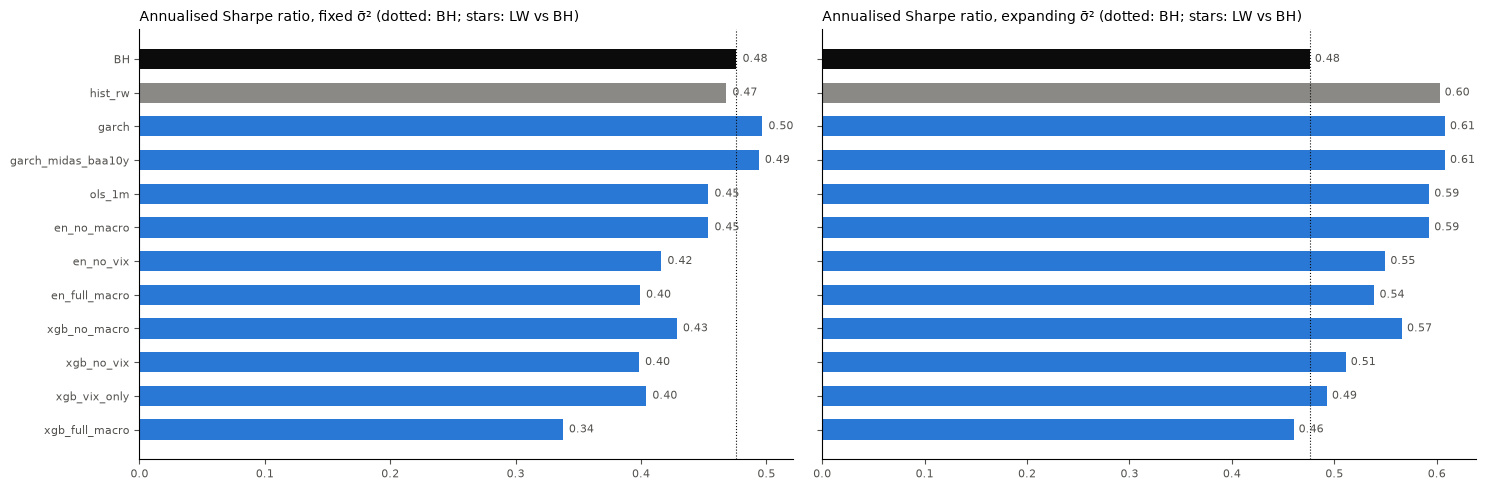

In [6]:
fig, axes = plt.subplots(1, len(SPECS), figsize=(15, 5), sharey=True, squeeze=False)
for ax, spec in zip(axes.flat, SPECS):
    sr = vs_bh[spec].loc[[BH] + MODELS, "ann_sharpe"]
    colors = ["#0b0b0b" if m == BH else "#8a8985" if m == BENCHMARK else "#2a78d6" for m in sr.index]
    ax.barh(sr.index[::-1], sr.values[::-1], color=colors[::-1], height=0.6)
    ax.axvline(sr[BH], color="#0b0b0b", linewidth=0.8, linestyle=":")
    for i, (m, v) in enumerate(sr[::-1].items()):
        ax.text(v + 0.005, i, f"{v:.2f}{stars(vs_bh[spec].at[m, 'LW_p']) if m != BH else ''}",
                va="center", fontsize=8, color="#52514e")
    ax.set_title(f"Annualised Sharpe ratio, {spec} σ̄² (dotted: BH; stars: LW vs BH)", fontsize=10, loc="left")
    ax.tick_params(labelsize=8, colors="#52514e")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

**Interpretation.** Under the fixed σ̄², **no managed portfolio beats buy-and-hold
significantly** (every Ledoit-Wolf p-value is above 0.4). Only the two GARCH portfolios have a
Sharpe ratio above BH (about 0.50 against 0.48). `hist_rw`, the simplest volatility timing, is
essentially level with BH.

The ranking runs from the historical models down to the macro-aware ones. GARCH comes first, then
HAR-OLS and `hist_rw`, then Elastic Net with macro, and XGBoost with full macro is last. **Every
macro-aware model sits below both benchmarks.** What volatility timing does deliver is lower
risk in the tails: every managed bucket except `en_no_vix` has a smaller maximum drawdown than BH
(−46% for GARCH against −56%), at the same volatility.

`hist_rw` is at the cap in 21% of ETF-months, against 1–5% for the fitted models. A one-month RV
is a noisy forecast, so a calm month often pushes the weight to its limit. Under the expanding σ̄²
every Sharpe ratio rises by 0.09–0.14. Part C shows that rise is re-levering, not forecast skill.

## A.1 B0: Volatility-timing baseline

**Question: Does the simplest volatility timing beat buy-and-hold, and does fitting a historical-volatility model improve on it?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B0.1 | `garch` | `hist_rw` | fitted GARCH vs naive history |
| B0.2 | `ols_1m` | `hist_rw` | fitted AR(1) on log RV vs naive history |

B0 Volatility-timing baseline: Does the simplest volatility timing beat buy-and-hold, and does fitting a historical-volatility model improve on it?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
garch,0.497,0.021,0.912,2.449,0.787,0.029,0.469,-45.791,0.410,4.393,0.608,0.489
ols_1m,0.454,-0.022,0.914,1.626,0.505,-0.014,0.673,-52.704,0.499,5.421,0.593,0.532



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B0.1,garch,hist_rw,fitted GARCH vs naive history,0.497,0.468,0.029,0.736,0.469,,n.s.,0.005,0.894,n.s.,True
B0.2,ols_1m,hist_rw,fitted AR(1) on log RV vs naive history,0.454,0.468,-0.014,-0.449,0.673,,n.s.,-0.010,0.598,n.s.,True


B0.1: no significant difference between garch and hist_rw (ΔSR +0.029, p = 0.469)   [expanding: ΔSR +0.005, p = 0.894]
B0.2: no significant difference between ols_1m and hist_rw (ΔSR -0.014, p = 0.673)   [expanding: ΔSR -0.010, p = 0.598]


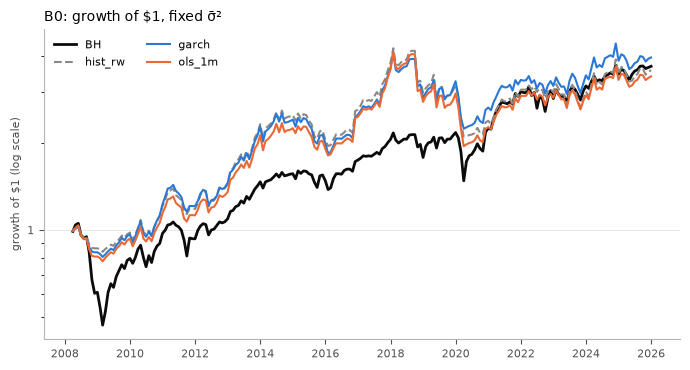

In [7]:
show_block("B0")

**Interpretation.** **Fitting a historical-volatility model does not give a significantly better
portfolio than the naive random walk.** GARCH is slightly ahead (ΔSR +0.03, p = 0.47) and HAR-OLS
slightly behind (−0.01, p = 0.67), under both specifications.

GARCH reaches a similar or higher Sharpe ratio with less trading: turnover is 0.41 against 0.49
for `hist_rw`, and the cap binds in 4% of ETF-months instead of 21%. So a smoother forecast keeps
the timing benefit at a lower cost. Per ETF, GARCH is ahead of `hist_rw` in XLB, XLF and XLI
(B.2), but never significantly. This sets the bar for the blocks below: the historical benchmarks
are hard to beat, and GARCH is the strongest of them.

## A.2 B1: GARCH family

**Question: Does macro information help within the GARCH family?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B1.1 | `garch_midas_baa10y` | `garch` | credit spread (BAA10Y) as the long-run component |

B1 GARCH family: Does macro information help within the GARCH family?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
garch,0.497,0.021,0.912,2.449,0.787,0.029,0.469,-45.791,0.410,4.393,0.608,0.489
garch_midas_baa10y,0.494,0.018,0.927,2.411,0.769,0.026,0.512,-46.149,0.412,4.579,0.608,0.492



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B1.1,garch_midas_baa10y,garch,credit spread (BAA10Y) as the long-run component,0.494,0.497,-0.003,-0.902,0.393,,n.s.,0.000,0.991,n.s.,False


B1.1: no significant difference between garch_midas_baa10y and garch (ΔSR -0.003, p = 0.393)   [expanding: ΔSR +0.000, p = 0.991]


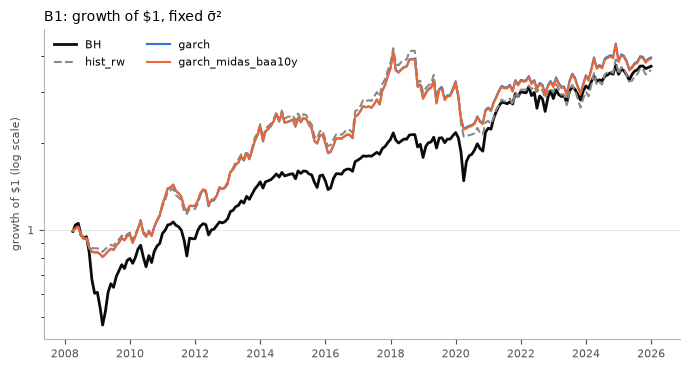

In [8]:
show_block("B1")

**Interpretation.** **Within the GARCH family, macro information does not help the portfolio.**
GARCH-MIDAS with the credit spread gives practically the same portfolio as GARCH (ΔSR −0.003,
p = 0.39; +0.000 under the expanding σ̄²). The two models' weights are almost identical (notebook
03, section 6b), so the long-run credit-spread component barely moves the month-to-month
forecast that drives the weights.

## A.3 B2: Macro information in a linear model

**Question: Do macro variables plus VIX help over the historical HAR benchmark?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B2.1 | `en_full_macro` | `ols_1m` | total effect of macro + VIX |

B2 Macro information in a linear model: Do macro variables plus VIX help over the historical HAR benchmark?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
ols_1m,0.454,-0.022,0.914,1.626,0.505,-0.014,0.673,-52.704,0.499,5.421,0.593,0.532
en_full_macro,0.399,-0.077,0.691,0.613,0.194,-0.069,0.230,-52.151,0.338,3.271,0.539,0.725



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B2.1,en_full_macro,ols_1m,total effect of macro + VIX,0.399,0.454,-0.055,-1.362,0.179,,n.s.,-0.054,0.120,n.s.,True


B2.1: no significant difference between en_full_macro and ols_1m (ΔSR -0.055, p = 0.179)   [expanding: ΔSR -0.054, p = 0.120]


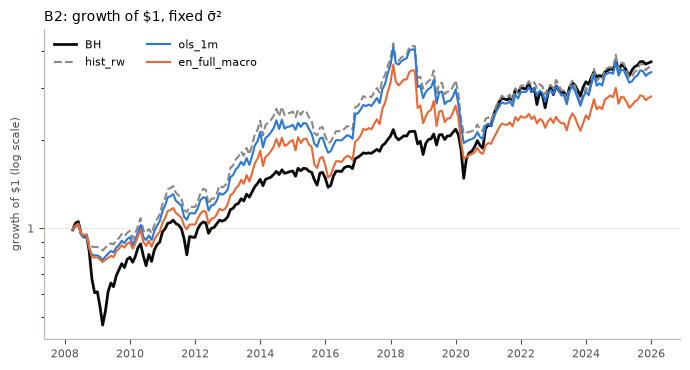

In [9]:
show_block("B2")

**Interpretation.** **Adding macro variables and VIX to a linear model does not improve the
portfolio. If anything it makes it worse.** The full-macro Elastic Net trails HAR-OLS by 0.055 in
Sharpe ratio. That is not significant (p = 0.18; 0.12 under the expanding σ̄²), but the sign is
negative in all five ETFs (B.2) and under both specifications. The direction is consistent; it is
not noise around zero.

## A.4 B3: Effect of VIX, Elastic Net

**Question: Is VIX doing all the work, or do the other macro variables add information?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B3.1 | `en_full_macro` | `en_no_vix` | VIX on top of the other macro variables |
| B3.2 | `en_vix_only` | `en_no_macro` | VIX on its own |
| B3.3 | `en_full_macro` | `en_vix_only` | other macro variables on top of VIX |

**How to read B3 and B4** (the 2×2 of VIX × other macro variables):

| Pattern | Conclusion |
|---|---|
| VIX-only beats no-macro, and full ≈ VIX-only | VIX is doing all the work |
| Full beats VIX-only | The other macro variables add information beyond VIX |
| Full beats no-VIX | VIX adds information beyond the other macro variables |
| All ≈ 0 | Neither helps the portfolio |

B3 Effect of VIX, Elastic Net: Is VIX doing all the work, or do the other macro variables add information?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
en_no_macro,0.454,-0.022,0.914,1.625,0.505,-0.014,0.675,-52.705,0.499,5.327,0.593,0.532
en_no_vix,0.416,-0.060,0.764,0.787,0.242,-0.052,0.389,-55.741,0.369,4.766,0.550,0.679
en_full_macro,0.399,-0.077,0.691,0.613,0.194,-0.069,0.230,-52.151,0.338,3.271,0.539,0.725



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B3.1,en_full_macro,en_no_vix,VIX on top of the other macro variables,0.399,0.416,-0.017,-0.407,0.703,,n.s.,-0.011,0.811,n.s.,True


B3.1: no significant difference between en_full_macro and en_no_vix (ΔSR -0.017, p = 0.703)   [expanding: ΔSR -0.011, p = 0.811]
B3.2: skipped, en_vix_only not built yet (en_vix_only vs en_no_macro)
B3.3: skipped, en_vix_only not built yet (en_full_macro vs en_vix_only)


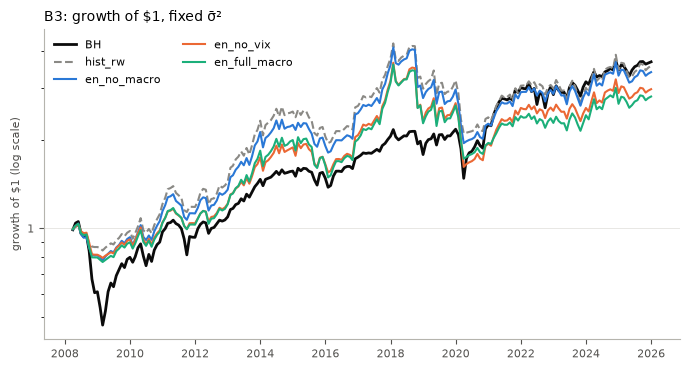

In [10]:
show_block("B3")

**Interpretation (provisional, since `en_vix_only` is not built yet).** The one pair that can be
tested, B3.1, shows that **adding VIX on top of the other macro variables does not help the Elastic
Net portfolio** (ΔSR −0.017, p = 0.70, the same sign under both specifications). The point
estimates in the table point the same way: `en_no_vix` (0.416) is below `en_no_macro` (0.454), and
`en_full_macro` (0.399) is lower again. Each addition of information lowers the Sharpe ratio a
little.

Whether VIX on its own helps (B3.2), and whether VIX is doing all the work (B3.3), can only be
answered once `en_vix_only` is exported. B4 answers the same questions for XGBoost in the meantime.

## A.5 B4: Effect of VIX, XGBoost (robustness check for B3)

**Question: Do the B3 findings hold with a non-linear model?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B4.0 | `xgb_full_macro` | `xgb_no_macro` | total effect of macro + VIX |
| B4.1 | `xgb_full_macro` | `xgb_no_vix` | VIX on top of the other macro variables |
| B4.2 | `xgb_vix_only` | `xgb_no_macro` | VIX on its own |
| B4.3 | `xgb_full_macro` | `xgb_vix_only` | other macro variables on top of VIX |

**How to read B3 and B4** (the 2×2 of VIX × other macro variables):

| Pattern | Conclusion |
|---|---|
| VIX-only beats no-macro, and full ≈ VIX-only | VIX is doing all the work |
| Full beats VIX-only | The other macro variables add information beyond VIX |
| Full beats no-VIX | VIX adds information beyond the other macro variables |
| All ≈ 0 | Neither helps the portfolio |

B4 Effect of VIX, XGBoost (robustness check for B3): Do the B3 findings hold with a non-linear model?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
xgb_no_macro,0.428,-0.048,0.769,0.611,0.233,-0.040,0.570,-50.723,0.423,1.495,0.566,0.550
xgb_no_vix,0.398,-0.078,0.652,0.076,0.026,-0.070,0.452,-53.062,0.328,1.121,0.511,0.824
xgb_vix_only,0.404,-0.072,0.665,0.406,0.144,-0.064,0.406,-48.833,0.385,2.804,0.493,0.916
xgb_full_macro,0.337,-0.139,0.404,-0.907,-0.319,-0.131,0.174,-53.318,0.332,1.963,0.460,0.921



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B4.0,xgb_full_macro,xgb_no_macro,total effect of macro + VIX,0.337,0.428,-0.091,-1.836,0.077,*,a worse,-0.106,0.013,a worse,True
B4.1,xgb_full_macro,xgb_no_vix,VIX on top of the other macro variables,0.337,0.398,-0.061,-1.240,0.263,,n.s.,-0.051,0.186,n.s.,True
B4.2,xgb_vix_only,xgb_no_macro,VIX on its own,0.404,0.428,-0.024,-0.551,0.591,,n.s.,-0.073,0.039,a worse,True
B4.3,xgb_full_macro,xgb_vix_only,other macro variables on top of VIX,0.337,0.404,-0.067,-1.969,0.064,*,a worse,-0.033,0.319,n.s.,True


B4.0: xgb_full_macro gives a weakly significantly worse portfolio than xgb_no_macro (ΔSR -0.091, p = 0.077)   [expanding: ΔSR -0.106, p = 0.013]
B4.1: no significant difference between xgb_full_macro and xgb_no_vix (ΔSR -0.061, p = 0.263)   [expanding: ΔSR -0.051, p = 0.186]
B4.2: no significant difference between xgb_vix_only and xgb_no_macro (ΔSR -0.024, p = 0.591)   [expanding: ΔSR -0.073, p = 0.039]
B4.3: xgb_full_macro gives a weakly significantly worse portfolio than xgb_vix_only (ΔSR -0.067, p = 0.064)   [expanding: ΔSR -0.033, p = 0.319]


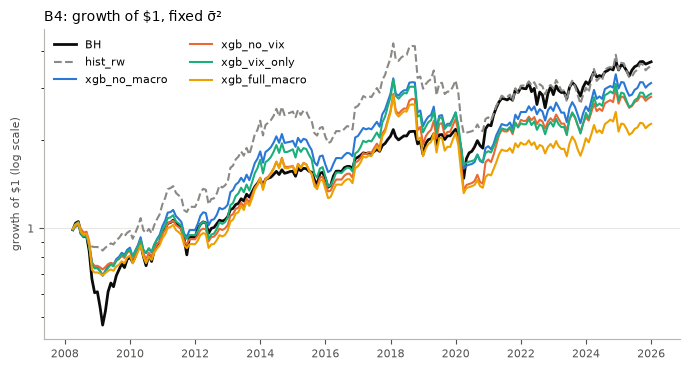

In [11]:
show_block("B4")

**Interpretation.** **In XGBoost, neither VIX nor the other macro variables improve the
portfolio, and together they make it worse.** All four differences are negative:

- **Total effect (B4.0):** full macro + VIX lowers the Sharpe ratio by 0.09 (p = 0.08; p = 0.01
  under the expanding σ̄²). This is the clearest result in the portfolio evaluation.
- **VIX on its own (B4.2):** −0.02, not significant under the fixed σ̄² (p = 0.04 under the
  expanding one). VIX alone does not help.
- **Other macro on top of VIX (B4.3):** −0.07 (p = 0.06). The non-VIX variables are the larger
  drag.
- **VIX on top of other macro (B4.1):** −0.06, not significant.

Using the reading key, the pattern is "all ≤ 0": VIX is not doing the work, because there is no
positive work to do. As a robustness check for B3, XGBoost agrees in direction with B3.1: adding
VIX to the other macro variables does not help.

## A.6 B5: Non-linearity

**Question: With the same information, does XGBoost beat Elastic Net?**

| Pair | a | b | Isolates |
|---|---|---|---|
| B5.1 | `xgb_no_macro` | `en_no_macro` | no macro |
| B5.2 | `xgb_no_vix` | `en_no_vix` | macro without VIX |
| B5.3 | `xgb_vix_only` | `en_vix_only` | VIX only |
| B5.4 | `xgb_full_macro` | `en_full_macro` | full macro + VIX |

B5 Non-linearity: With the same information, does XGBoost beat Elastic Net?

Bucket portfolios against the benchmarks (fixed σ̄²; last two columns: expanding):


,SR,ΔSR vs BH,p vs BH,α % p.a.,α t,ΔSR vs hist_rw,p vs hist_rw,MaxDD %,turnover,% capped,SR (expanding),p vs BH (expanding)
portfolio,,,,,,,,,,,,
BH,0.476,NaN,NaN,NaN,NaN,NaN,NaN,-55.519,0.000,NaN,0.476,NaN
hist_rw,0.468,-0.008,0.969,2.175,0.644,NaN,NaN,-50.558,0.493,21.308,0.603,0.520
en_no_macro,0.454,-0.022,0.914,1.625,0.505,-0.014,0.675,-52.705,0.499,5.327,0.593,0.532
xgb_no_macro,0.428,-0.048,0.769,0.611,0.233,-0.040,0.570,-50.723,0.423,1.495,0.566,0.550
en_no_vix,0.416,-0.060,0.764,0.787,0.242,-0.052,0.389,-55.741,0.369,4.766,0.550,0.679
xgb_no_vix,0.398,-0.078,0.652,0.076,0.026,-0.070,0.452,-53.062,0.328,1.121,0.511,0.824
xgb_vix_only,0.404,-0.072,0.665,0.406,0.144,-0.064,0.406,-48.833,0.385,2.804,0.493,0.916
en_full_macro,0.399,-0.077,0.691,0.613,0.194,-0.069,0.230,-52.151,0.338,3.271,0.539,0.725
xgb_full_macro,0.337,-0.139,0.404,-0.907,-0.319,-0.131,0.174,-53.318,0.332,1.963,0.460,0.921



Pair tests, SR(a) = SR(b):


,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,
B5.1,xgb_no_macro,en_no_macro,no macro,0.428,0.454,-0.025,-0.523,0.630,,n.s.,-0.027,0.529,n.s.,True
B5.2,xgb_no_vix,en_no_vix,macro without VIX,0.398,0.416,-0.018,-0.325,0.758,,n.s.,-0.039,0.316,n.s.,True
B5.4,xgb_full_macro,en_full_macro,full macro + VIX,0.337,0.399,-0.062,-1.220,0.273,,n.s.,-0.079,0.123,n.s.,True


B5.1: no significant difference between xgb_no_macro and en_no_macro (ΔSR -0.025, p = 0.630)   [expanding: ΔSR -0.027, p = 0.529]
B5.2: no significant difference between xgb_no_vix and en_no_vix (ΔSR -0.018, p = 0.758)   [expanding: ΔSR -0.039, p = 0.316]
B5.4: no significant difference between xgb_full_macro and en_full_macro (ΔSR -0.062, p = 0.273)   [expanding: ΔSR -0.079, p = 0.123]
B5.3: skipped, en_vix_only not built yet (xgb_vix_only vs en_vix_only)


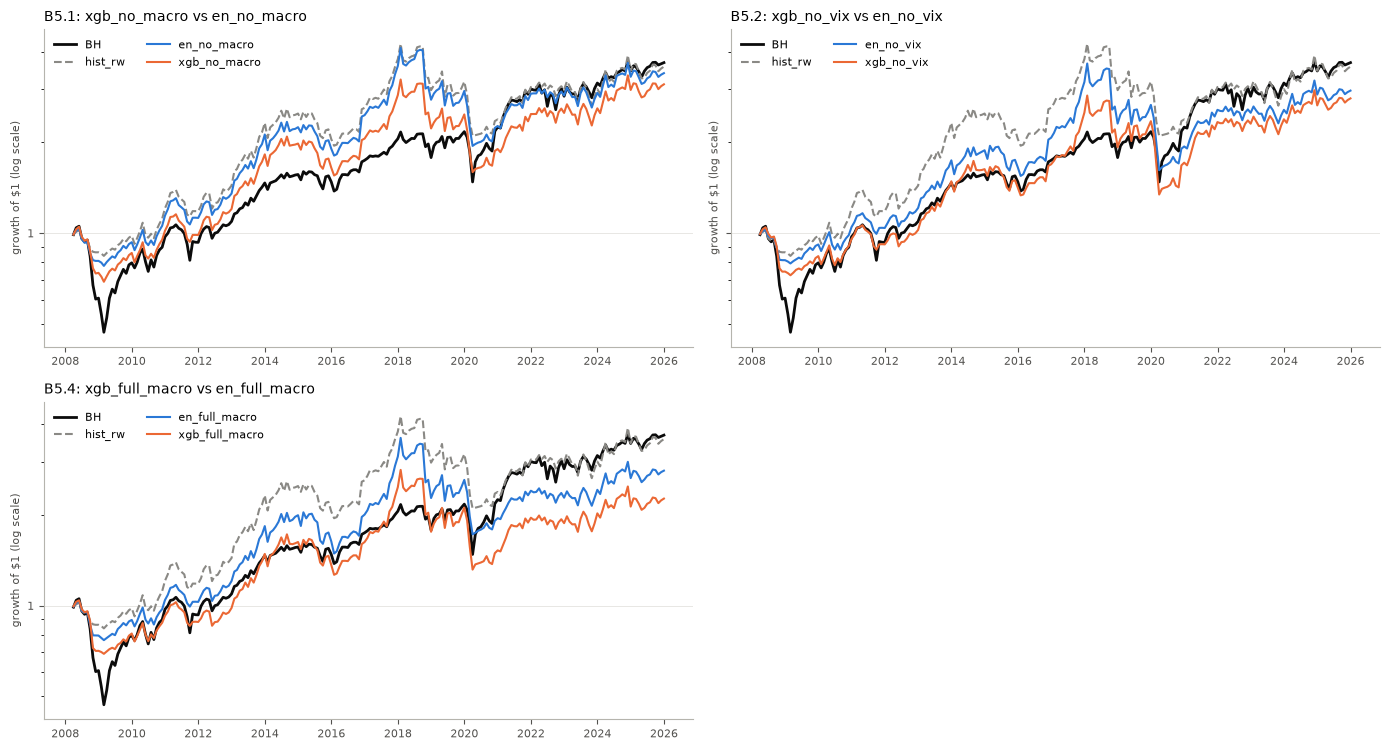

In [12]:
show_block("B5")

**Interpretation.** **Non-linearity does not add portfolio value.** XGBoost is below Elastic Net
for every information set (no macro −0.03, macro without VIX −0.02, full macro −0.06). None of the
differences is significant, and all keep their sign under the expanding σ̄². The gap is largest
with the full feature set, where XGBoost has the most variables to overfit.

## A.7 Bucket scoreboard

Every pair in one table: the answer to each sub-question on the portfolio side. `result` is
"a better" or "a worse" when the Ledoit-Wolf p-value is below 0.10, and "n.s." otherwise.
`same sign` checks the direction of ΔSR under the expanding σ̄².

In [13]:
scoreboard = pair_rows()
scoreboard.insert(1, "question", [BLOCKS[b]["title"] for b in scoreboard["block"]])
scoreboard

,block,question,a,b,isolates,SR_a,SR_b,ΔSR,LW t,p,sig,result,ΔSR (expanding),p (expanding),result (expanding),same sign
pair,,,,,,,,,,,,,,,,
B0.1,B0,Volatility-timing baseline,garch,hist_rw,fitted GARCH vs naive history,0.497,0.468,0.029,0.736,0.469,,n.s.,0.005,0.894,n.s.,True
B0.2,B0,Volatility-timing baseline,ols_1m,hist_rw,fitted AR(1) on log RV vs naive history,0.454,0.468,-0.014,-0.449,0.673,,n.s.,-0.010,0.598,n.s.,True
B1.1,B1,GARCH family,garch_midas_baa10y,garch,credit spread (BAA10Y) as the long-run component,0.494,0.497,-0.003,-0.902,0.393,,n.s.,0.000,0.991,n.s.,False
B2.1,B2,Macro information in a linear model,en_full_macro,ols_1m,total effect of macro + VIX,0.399,0.454,-0.055,-1.362,0.179,,n.s.,-0.054,0.120,n.s.,True
B3.1,B3,"Effect of VIX, Elastic Net",en_full_macro,en_no_vix,VIX on top of the other macro variables,0.399,0.416,-0.017,-0.407,0.703,,n.s.,-0.011,0.811,n.s.,True
B4.0,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_full_macro,xgb_no_macro,total effect of macro + VIX,0.337,0.428,-0.091,-1.836,0.077,*,a worse,-0.106,0.013,a worse,True
B4.1,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_full_macro,xgb_no_vix,VIX on top of the other macro variables,0.337,0.398,-0.061,-1.240,0.263,,n.s.,-0.051,0.186,n.s.,True
B4.2,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_vix_only,xgb_no_macro,VIX on its own,0.404,0.428,-0.024,-0.551,0.591,,n.s.,-0.073,0.039,a worse,True
B4.3,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_full_macro,xgb_vix_only,other macro variables on top of VIX,0.337,0.404,-0.067,-1.969,0.064,*,a worse,-0.033,0.319,n.s.,True


**Interpretation: the portfolio half of the research question.** Across the 12 pairs, **no
addition gives a significantly better portfolio**. Eleven of the twelve ΔSRs are negative. The
one positive is GARCH against `hist_rw` (+0.03, n.s.), and GARCH-MIDAS against GARCH (−0.003) is
effectively zero. The only significant results are both negative and both in XGBoost: adding
macro + VIX (B4.0) and adding the other macro variables on top of VIX (B4.3), each at the 10%
level.

So, on the portfolio side, **macro-aware forecasts do not translate into better risk-adjusted
performance than the historical-volatility benchmarks**, and richer information sets tend to make
the portfolio slightly worse. Notebook 03 asks whether that is because the forecasts themselves are
no better, or because forecast gains are lost on the way to the portfolio.

# Part B: Per-ETF portfolios

Each ETF's managed series positionᵢ,ₜ₊₁ is rescaled by cᵢ = σ(rᵢ − rf) / σ(positionᵢ) to the
volatility of that ETF's own buy-and-hold, so every comparison is at matched risk. cᵢ does not
change the Sharpe ratio or the Ledoit-Wolf test. The `Cyclical` column repeats the bucket result
for reference. The heatmaps show the main (fixed) specification; the full tables for both are in
B.4.

## B.1 Against buy-and-hold and against `hist_rw`

ΔSR of each model's managed ETF against that ETF's buy-and-hold (left) and against the `hist_rw`
portfolio for the same ETF (right). Blue: the model is better.

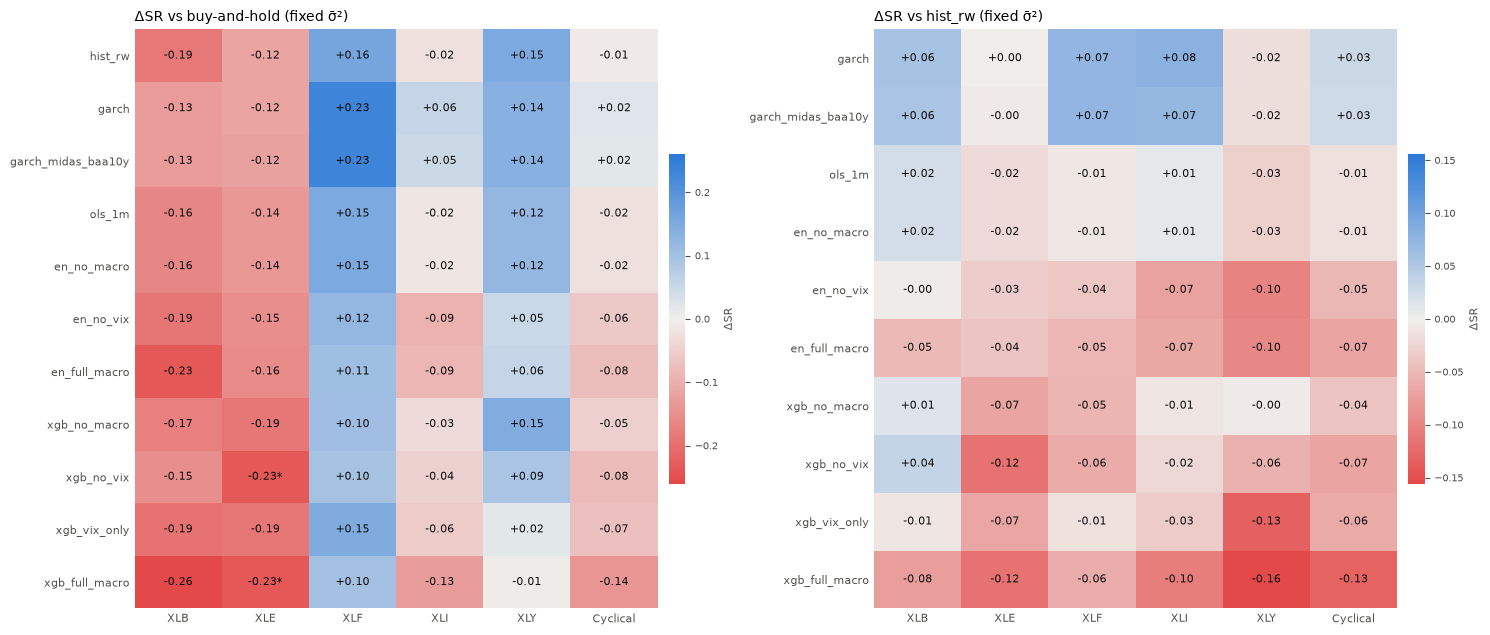

In [14]:
units = TICKERS + ["Cyclical"]
etf_main = vs_bh_etf[MAIN_SPEC]
d_bh = etf_main["SR_diff"].unstack("ETF").loc[MODELS, TICKERS]
p_bh = etf_main["LW_p"].unstack("ETF").loc[MODELS, TICKERS]
d_bh["Cyclical"] = vs_bh[MAIN_SPEC].loc[MODELS, "SR_diff_vs_BH"]
p_bh["Cyclical"] = vs_bh[MAIN_SPEC].loc[MODELS, "LW_p"]

others = [m for m in MODELS if m != BENCHMARK]
vs_rw = lw.loc[MAIN_SPEC].xs(BENCHMARK, level="b").loc[others]
d_rw = vs_rw["SR_diff"].unstack("ETF").loc[others, units]
p_rw = vs_rw["LW_p"].unstack("ETF").loc[others, units]

fig, axes = plt.subplots(1, 2, figsize=(15, 0.45 * len(MODELS) + 1.5))
heatmap(d_bh, p_bh, axes[0], f"ΔSR vs buy-and-hold ({MAIN_SPEC} σ̄²)")
heatmap(d_rw, p_rw, axes[1], f"ΔSR vs {BENCHMARK} ({MAIN_SPEC} σ̄²)")
fig.tight_layout()
plt.show()

## B.2 Block pairs per ETF

ΔSR = SR(a) − SR(b) for every block pair and ETF. Blue: the richer model a gives the better
portfolio. The rows are grouped by block.

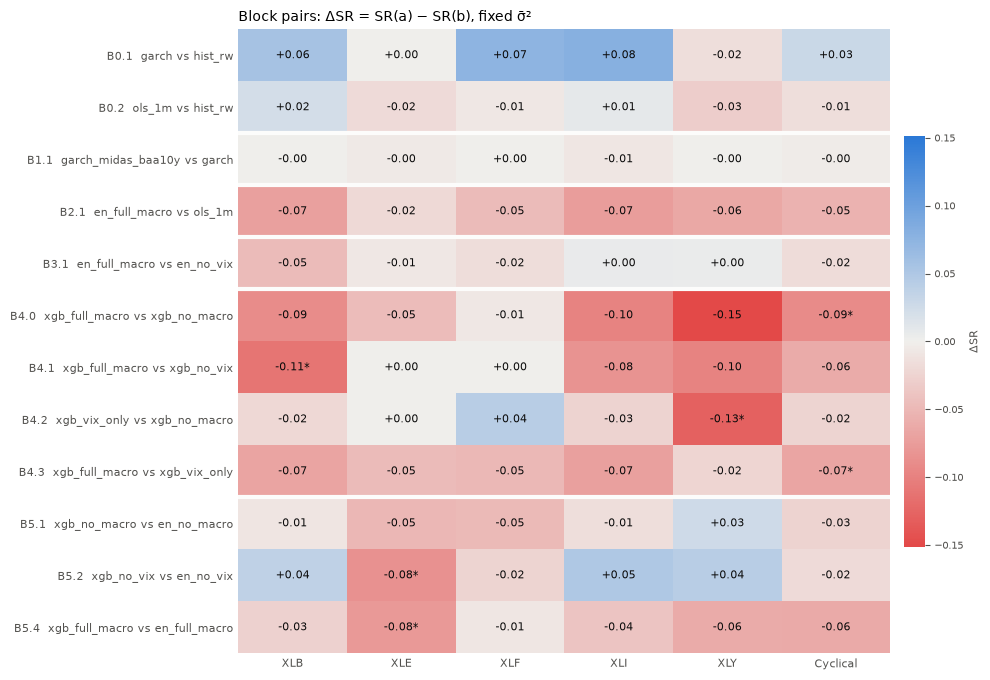

In [15]:
pair_etf = {}
for spec in SPECS:
    sub = lw.loc[spec]
    idx = [(p.a, p.b) for _, p in pairs.iterrows()]
    labels = [f"{pid}  {p.a} vs {p.b}" for pid, p in pairs.iterrows()]
    pair_etf[spec] = {
        "SR_diff": pd.DataFrame([sub.loc[i, "SR_diff"][units].values for i in idx], index=labels, columns=units),
        "LW_p": pd.DataFrame([sub.loc[i, "LW_p"][units].values for i in idx], index=labels, columns=units),
    }

fig, ax = plt.subplots(figsize=(10, 0.45 * len(pairs) + 1.5))
heatmap(pair_etf[MAIN_SPEC]["SR_diff"], pair_etf[MAIN_SPEC]["LW_p"], ax,
        f"Block pairs: ΔSR = SR(a) − SR(b), {MAIN_SPEC} σ̄²")
breaks = np.flatnonzero(pairs["block"].to_numpy()[1:] != pairs["block"].to_numpy()[:-1])
for y in breaks:
    ax.axhline(y + 0.5, color="#fcfcfb", linewidth=3)
fig.tight_layout()
plt.show()

## B.3 What the per-ETF results say


**Against buy-and-hold (B.1, left)**, the bucket's near-zero result hides a split by sector.
Volatility timing helps in **XLF and XLY**, where most models are ahead of their ETF's own BH
(XLF +0.10 to +0.23). It hurts in **XLB and XLE**, where every model is behind (−0.12 to −0.26).
The XLE losses are significant for two XGBoost models. A likely reason: in financials and
consumer discretionary, high volatility has come with falling prices (2008, 2020), the situation
volatility timing exploits. Materials and energy follow commodity cycles, where cutting exposure
after a volatility spike can mean missing the rebound.

**Against `hist_rw` (B.1, right)**, GARCH is the only model ahead in most sectors (XLB, XLF, XLI).
The macro-aware models are behind it in almost every ETF.

**Block pairs (B.2).** Macro information does not help in any single sector, including the ones
where a sector-specific story would predict it should, such as credit spreads for XLF or oil for
XLE. The total-macro rows (B2.1 for EN, B4.0 for XGB) are negative in all five ETFs. GARCH-MIDAS vs
GARCH is zero everywhere. The EN vs XGBoost rows (B5) are mixed per ETF, consistent with no
systematic advantage either way.

## B.4 Full per-ETF tables

Every model against its own ETF's buy-and-hold, under each specification (`LW_t`, `LW_p`: the
Ledoit-Wolf test; `alpha_*`: the alpha on that ETF's BH).

In [16]:
for spec in SPECS:
    print(f"--- {spec} σ̄² ---")
    display(vs_bh_etf[spec])

--- fixed σ̄² ---


c_i  SR_managed  SR_BH  SR_diff   LW_t  LW_p  alpha_annual  alpha_t  maxDD_managed  maxDD_BH  avg_turnover  pct_capped
model              ETF                                                                                                                         
hist_rw            XLB 1.010       0.176  0.361   -0.185 -1.063 0.347        -0.022   -0.656         -0.476    -0.559         0.421      23.832
                   XLE 1.033       0.119  0.237   -0.118 -0.801 0.437        -0.017   -0.435         -0.838    -0.660         0.359      24.766
                   XLF 1.141       0.522  0.363    0.159  0.667 0.561         0.061    1.342         -0.456    -0.708         0.508      28.037
                   XLI 1.266       0.527  0.550   -0.023 -0.120 0.911         0.023    0.675         -0.434    -0.555         0.586       9.813
                   XLY 1.209       0.822  0.671    0.151  0.739 0.483         0.069    1.956         -0.382    -0.454         0.516      20.093
garch              XLB 1.198       0.233  0.361   -0.129 -0.829 0.466        -0.013   -0.434         -0.429    -0.559         0.333       4.206
                   XLE 1.100       0.120  0.237   -0.117 -0.847 0.414        -0.018   -0.489         -0.833    -0.660         0.321       9.813
                   XLF 1.391       0.596  0.363    0.233  1.047 0.397         0.075    1.764         -0.336    -0.708         0.494       5.607
                   XLI 1.655       0.606  0.550    0.056  0.340 0.762         0.031    1.040         -0.327    -0.555         0.401       0.000
                   XLY 1.437       0.807  0.671    0.136  0.761 0.488         0.060    1.867         -0.310    -0.454         0.456       2.336
garch_midas_baa10y XLB 1.197       0.232  0.361   -0.130 -0.829 0.468        -0.013   -0.434         -0.432    -0.559         0.335       4.206
                   XLE 1.095       0.115  0.237   -0.122 -0.879 0.396        -0.019   -0.518         -0.835    -0.660         0.323      10.748
                   XLF 1.387       0.596  0.363    0.234  1.045 0.399         0.076    1.760         -0.335    -0.708         0.495       5.607
                   XLI 1.644       0.598  0.550    0.048  0.290 0.795         0.030    0.982         -0.332    -0.555         0.402       0.000
                   XLY 1.428       0.807  0.671    0.135  0.751 0.495         0.061    1.858         -0.312    -0.454         0.459       2.336
ols_1m             XLB 1.262       0.199  0.361   -0.163 -1.031 0.353        -0.020   -0.647         -0.522    -0.559         0.430       8.411
                   XLE 1.217       0.101  0.237   -0.136 -1.009 0.323        -0.024   -0.660         -0.845    -0.660         0.386       7.944
                   XLF 1.520       0.515  0.363    0.153  0.660 0.566         0.060    1.340         -0.450    -0.708         0.604       4.206
                   XLI 1.672       0.534  0.550   -0.016 -0.092 0.928         0.019    0.591         -0.437    -0.555         0.511       1.402
                   XLY 1.443       0.792  0.671    0.120  0.619 0.559         0.060    1.730         -0.400    -0.454         0.514       5.140
en_no_macro        XLB 1.262       0.199  0.361   -0.163 -1.031 0.354        -0.020   -0.646         -0.522    -0.559         0.430       8.411
                   XLE 1.217       0.101  0.237   -0.136 -1.009 0.323        -0.024   -0.660         -0.845    -0.660         0.385       7.477
                   XLF 1.522       0.516  0.363    0.153  0.661 0.565         0.060    1.341         -0.450    -0.708         0.603       4.206
                   XLI 1.673       0.534  0.550   -0.016 -0.093 0.928         0.019    0.590         -0.437    -0.555         0.511       1.402
                   XLY 1.443       0.792  0.671    0.121  0.620 0.559         0.059    1.731         -0.400    -0.454         0.514       5.140
en_no_vix          XLB 1.245       0.174  0.361   -0.188 -1.154 0.300        -0.025   -0.802         -0.545    -0.559         0.328      

--- expanding σ̄² ---


c_i  SR_managed  SR_BH  SR_diff   LW_t  LW_p  alpha_annual  alpha_t  maxDD_managed  maxDD_BH  avg_turnover  pct_capped
model              ETF                                                                                                                         
hist_rw            XLB 0.788       0.315  0.361   -0.046 -0.288 0.797         0.003    0.095         -0.390    -0.559         0.242      54.206
                   XLE 0.816       0.221  0.237   -0.015 -0.119 0.917         0.006    0.188         -0.787    -0.660         0.219      50.000
                   XLF 0.728       0.627  0.363    0.264  1.268 0.342         0.075    1.772         -0.341    -0.708         0.127      72.430
                   XLI 0.832       0.630  0.550    0.080  0.487 0.667         0.034    1.125         -0.380    -0.555         0.287      47.196
                   XLY 0.868       0.914  0.671    0.243  1.407 0.211         0.077    2.474         -0.258    -0.454         0.264      46.262
garch              XLB 0.819       0.301  0.361   -0.060 -0.400 0.720        -0.001   -0.047         -0.364    -0.559         0.226      38.318
                   XLE 0.816       0.226  0.237   -0.011 -0.090 0.937         0.007    0.214         -0.769    -0.660         0.187      43.925
                   XLF 0.738       0.632  0.363    0.270  1.341 0.322         0.076    1.885         -0.342    -0.708         0.117      71.495
                   XLI 0.868       0.657  0.550    0.108  0.649 0.563         0.039    1.264         -0.295    -0.555         0.257      35.981
                   XLY 0.897       0.905  0.671    0.234  1.441 0.203         0.073    2.457         -0.234    -0.454         0.265      37.850
garch_midas_baa10y XLB 0.819       0.302  0.361   -0.059 -0.390 0.726        -0.001   -0.036         -0.365    -0.559         0.226      38.785
                   XLE 0.816       0.225  0.237   -0.011 -0.091 0.936         0.007    0.214         -0.768    -0.660         0.188      44.860
                   XLF 0.738       0.633  0.363    0.270  1.333 0.325         0.076    1.873         -0.342    -0.708         0.117      71.495
                   XLI 0.866       0.655  0.550    0.105  0.629 0.574         0.038    1.236         -0.296    -0.555         0.257      36.449
                   XLY 0.896       0.907  0.671    0.236  1.438 0.203         0.073    2.446         -0.235    -0.454         0.265      38.318
ols_1m             XLB 0.875       0.283  0.361   -0.079 -0.532 0.629        -0.006   -0.195         -0.422    -0.559         0.304      29.907
                   XLE 0.875       0.202  0.237   -0.035 -0.289 0.788        -0.000   -0.007         -0.801    -0.660         0.252      31.776
                   XLF 0.784       0.639  0.363    0.276  1.320 0.321         0.078    1.861         -0.339    -0.708         0.173      62.150
                   XLI 0.925       0.646  0.550    0.096  0.612 0.578         0.035    1.215         -0.369    -0.555         0.353      28.037
                   XLY 0.948       0.907  0.671    0.236  1.415 0.207         0.073    2.413         -0.299    -0.454         0.308      31.776
en_no_macro        XLB 0.875       0.283  0.361   -0.079 -0.532 0.629        -0.006   -0.195         -0.422    -0.559         0.304      29.907
                   XLE 0.875       0.202  0.237   -0.035 -0.289 0.788        -0.000   -0.007         -0.801    -0.660         0.252      31.776
                   XLF 0.784       0.638  0.363    0.276  1.319 0.321         0.078    1.860         -0.340    -0.708         0.174      62.150
                   XLI 0.925       0.646  0.550    0.096  0.613 0.578         0.035    1.215         -0.369    -0.555         0.353      28.037
                   XLY 0.948       0.907  0.671    0.236  1.416 0.207         0.073    2.414         -0.299    -0.454         0.308      31.776
en_no_vix          XLB 0.867       0.266  0.361   -0.095 -0.630 0.571        -0.009   -0.316         -0.442    -0.559         0.237      

# Part C: Robustness, expanding reference σ̄²ᵢ,ₜ

**Why the main results use a fixed reference.** With a constant reference σ̄²ᵢ, the only thing
moving the weights from month to month is the forecast σ̂²ᵢ,ₜ₊₁. Comparing managed portfolios
across models is then a direct test of forecast skill, which is the research question. With an
expanding reference, σ̄²ᵢ,ₜ moves too, and the weights pick up a re-levering effect that has
nothing to do with the forecast. The Phase 2 proposal (Section 3) defines the reference as "the
ETF's average training-window variance"; the models' training window expands, so that wording also
admits the expanding mean, reported here as the alternative specification.

**What the expanding reference does and does not affect.** Within a pair, both models share the
same σ̄²ᵢ,ₜ, so the re-levering affects a and b alike and the pair tests remain tests of forecast
skill. The comparisons with buy-and-hold are where the specification matters.

## C.1 Do the pair results hold?

For each pair: the result under each specification, and the share of the five ETFs whose ΔSR has
the same sign under both.

In [17]:
etf_sign_agree = pd.Series({
    lbl: (np.sign(pair_etf[MAIN_SPEC]["SR_diff"].loc[lbl, TICKERS])
          == np.sign(pair_etf[ROBUST_SPEC]["SR_diff"].loc[lbl, TICKERS])).mean()
    for lbl in pair_etf[MAIN_SPEC]["SR_diff"].index})
robust = scoreboard[["block", "a", "b", "ΔSR", "p", "result", f"ΔSR ({ROBUST_SPEC})",
                     f"p ({ROBUST_SPEC})", f"result ({ROBUST_SPEC})", "same sign"]].copy()
robust["same result"] = robust["result"] == robust[f"result ({ROBUST_SPEC})"]
robust["ETFs same sign"] = etf_sign_agree.to_numpy()
robust

,block,a,b,ΔSR,p,result,ΔSR (expanding),p (expanding),result (expanding),same sign,same result,ETFs same sign
pair,,,,,,,,,,,,
B0.1,B0,garch,hist_rw,0.029,0.469,n.s.,0.005,0.894,n.s.,True,True,0.800
B0.2,B0,ols_1m,hist_rw,-0.014,0.673,n.s.,-0.010,0.598,n.s.,True,True,0.600
B1.1,B1,garch_midas_baa10y,garch,-0.003,0.393,n.s.,0.000,0.991,n.s.,False,True,0.600
B2.1,B2,en_full_macro,ols_1m,-0.055,0.179,n.s.,-0.054,0.120,n.s.,True,True,1.000
B3.1,B3,en_full_macro,en_no_vix,-0.017,0.703,n.s.,-0.011,0.811,n.s.,True,True,0.800
B4.0,B4,xgb_full_macro,xgb_no_macro,-0.091,0.077,a worse,-0.106,0.013,a worse,True,True,1.000
B4.1,B4,xgb_full_macro,xgb_no_vix,-0.061,0.263,n.s.,-0.051,0.186,n.s.,True,True,0.800
B4.2,B4,xgb_vix_only,xgb_no_macro,-0.024,0.591,n.s.,-0.073,0.039,a worse,True,False,0.600
B4.3,B4,xgb_full_macro,xgb_vix_only,-0.067,0.064,a worse,-0.033,0.319,n.s.,True,False,0.800


## C.2 Timing or re-levering?

Under the expanding reference, a managed portfolio's performance mixes two things: the re-levering
that comes from σ̄²ᵢ,ₜ rising after crises, and the timing that comes from the forecast. The
**control** captures only the first. It uses the same weight formula and cap, with the fixed
2003-03 to 2008-02 reference in place of σ̂²:

w^ctrl_{i,t} = min(σ̄²ᵢ,ₜ / σ̄²ᵢ,fixed, 2).

It starts at 1 and rises only when the expanding mean rises. One regression per model, with
Newey-West standard errors:

f^σ_t = α + β_BH · BH_t + β_ctrl · control_t + εₜ.

**α is what the forecast adds beyond holding the ETFs and beyond re-levering.** For the control
row, α and β_BH come from a regression on BH alone; its fixed-specification entries are empty,
since under the fixed reference the control is identically buy-and-hold.

**% capped** under each specification shows how much of the expanding version is leverage: a
model at the cap far more often under the expanding reference is mostly being re-levered, not
timed.

In [18]:
exp_res = portfolios["expanding"]
control = exp_res[CONTROL]

rows = {}
for m in MODELS:
    rows[m] = {
        "SR_fixed": vs_bh["fixed"].at[m, "ann_sharpe"],
        "SR_expanding": vs_bh["expanding"].at[m, "ann_sharpe"],
        **alpha_vs_bh_and_control(exp_res[m], bh, control),
        "pct_capped_fixed": pct_capped_pooled(portfolios["fixed"][m]["weights_base"], K_CAP),
        "pct_capped_expanding": pct_capped_pooled(exp_res[m]["weights_base"], K_CAP),
    }

al = alpha_regression(control["managed"], bh.to_frame("BH"))
rows[CONTROL] = {
    "SR_fixed": np.nan,
    "SR_expanding": performance_row(control["managed"], control["bucket_weights"])["ann_sharpe"],
    "alpha_annual": al["alpha_annual"], "alpha_t": al["alpha_t"], "alpha_p": al["alpha_p"],
    "beta_BH": al["beta_BH"], "beta_control": np.nan, "R2": al["R2"],
    "pct_capped_fixed": np.nan,
    "pct_capped_expanding": pct_capped_pooled(control["weights_base"], K_CAP),
}

extension = pd.DataFrame(rows).T.rename_axis("portfolio")
extension = extension[["SR_fixed", "SR_expanding", "alpha_annual", "alpha_t", "alpha_p",
                       "beta_BH", "beta_control", "R2", "pct_capped_fixed", "pct_capped_expanding"]]
extension

,SR_fixed,SR_expanding,alpha_annual,alpha_t,alpha_p,beta_BH,beta_control,R2,pct_capped_fixed,pct_capped_expanding
portfolio,,,,,,,,,,
hist_rw,0.468,0.603,0.029,1.016,0.310,0.082,0.751,0.694,21.308,54.019
garch,0.497,0.608,0.027,1.018,0.309,-0.054,0.894,0.707,4.393,45.514
garch_midas_baa10y,0.494,0.608,0.027,1.011,0.312,-0.060,0.899,0.706,4.579,45.981
ols_1m,0.454,0.593,0.028,1.018,0.309,0.256,0.589,0.713,5.421,36.729
en_no_macro,0.454,0.593,0.028,1.018,0.309,0.257,0.588,0.713,5.327,36.729
en_no_vix,0.416,0.550,0.025,0.884,0.377,0.653,0.196,0.720,4.766,33.271
en_full_macro,0.399,0.539,0.023,0.831,0.406,0.491,0.336,0.682,3.271,36.075
xgb_no_macro,0.428,0.566,0.023,0.984,0.325,0.521,0.358,0.770,1.495,39.813
xgb_no_vix,0.398,0.511,0.022,0.821,0.412,1.021,-0.158,0.746,1.121,31.308


**Interpretation.** **The pair results hold under the expanding σ̄².** 10 of the 12 pairs give the same
result under both specifications, and 11 of 12 keep their sign. The exception is B1.1, whose ΔSR
is zero under both. Two results shift: B4.2 (VIX alone in XGBoost) becomes significantly negative
(p = 0.04), and B4.3 loses its 10% significance. Neither changes the
conclusion that the additions do not help.

**The gains against BH under the expanding σ̄² are re-levering, not forecast skill.** Every
Sharpe ratio rises by 0.09–0.14, `hist_rw`'s included, and the share of ETF-months at the cap
jumps from 1–21% to 31–54%. The control alone, which uses no forecast at all, reaches a Sharpe ratio
of 0.55 with a significant alpha on BH (t = 2.15). Once the control is in the regression, **no
model has a significant alpha** (every t ≤ 1.02). So the expanding reference makes volatility
timing look better against BH by levering up after crises. It does not change which forecast gives
the better portfolio.

## Save the tables

Written to `results/eval/`:

- `vs_benchmarks_bucket_<spec>.csv`: every bucket portfolio against BH (performance, LW, alpha)
  and against `hist_rw` (`SR_diff_vs_RW`, `LW_t_vs_RW`, `LW_p_vs_RW`);
- `vs_benchmarks_per_etf_<spec>.csv`: the same per ETF (read by notebook 03);
- `pairs.csv`: every block-pair test, long (spec, block, pair, a, b, ETF), including the bucket
  (read by notebook 03);
- `scoreboard_bucket.csv`: the bucket scoreboard;
- `extension.csv`: the control regressions.

In [19]:
EVAL_DIR.mkdir(parents=True, exist_ok=True)
for spec in SPECS:
    rw = lw.loc[spec].xs(BENCHMARK, level="b")[["SR_diff", "LW_t", "LW_p"]].add_suffix("_vs_RW")
    vs_bh[spec].join(rw.xs("Cyclical", level="ETF")).to_csv(EVAL_DIR / f"vs_benchmarks_bucket_{spec}.csv")
    vs_bh_etf[spec].join(rw.rename_axis(["model", "ETF"])).to_csv(EVAL_DIR / f"vs_benchmarks_per_etf_{spec}.csv")

pairs_long = pd.concat(
    {(spec, p.block, pid, p.a, p.b): lw.loc[(spec, p.a, p.b)] for spec in SPECS for pid, p in pairs.iterrows()},
    names=["spec", "block", "pair", "a", "b"])
pairs_long.to_csv(EVAL_DIR / "pairs.csv")
scoreboard.to_csv(EVAL_DIR / "scoreboard_bucket.csv")
extension.to_csv(EVAL_DIR / "extension.csv")
print("Saved to", EVAL_DIR.resolve())

Saved to C:\Documents\NUS\Y4S1\DSE4101\dse4101capstone_project\models\portfolio_construction\results\eval
